# TanggapMakna — Local Challenge Set Evaluation

## FINAL AI EVALUATION BEFORE WEB DEVELOPMENT

Notebook ini **tidak melakukan training** dan **tidak mengubah ground truth**.

### Input
1. Checkpoint terbaik IndoBERT V2: `TanggapMakna_IndoBERT_V2.zip`
2. Workbook ground truth final yang sudah dikunci, misalnya:
   `TanggapMakna_Local_Challenge_Set_GROUND_TRUTH_FINAL_LOCKED_QA_v0.8.xlsx`

### Tujuan
Mengukur apakah IndoBERT V2 yang dilatih pada dataset krisis Twitter tetap berguna pada **60 laporan bergaya input web**.

### Evaluasi
- Event Status macro-F1
- Event Type macro-F1 pada actual-event
- False-event binary F1
- Location token-F1 (`PLACE + STREET`)
- Time token-F1
- Impact token-F1 (`AFFECTED_OBJECTS + INFORMATION`)
- Victim token-F1 (`DEATH + WOUND`)
- Metrik per semantic role
- Error analysis per laporan

> **PENTING:** 60 laporan ini adalah *synthetic/product stress test*, bukan dataset lapangan representatif.
> Hasilnya dipakai sebagai bukti feasibility/generalization produk, bukan klaim populasi Indonesia.

## 1. Setup environment

In [ ]:
!nvidia-smi

# Jangan upgrade paket inti Colab.
!pip install -q transformers openpyxl scikit-learn xlsxwriter

import os
import re
import json
import math
import shutil
import zipfile
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score,
)

from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 76)
print("TANGGAPMAKNA — LOCAL CHALLENGE EVALUATION")
print("=" * 76)
print("Device :", DEVICE)

if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))

print("PyTorch:", torch.__version__)

/bin/bash: line 1: nvidia-smi: command not found
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 3.1 MB/s eta 0:00:00
TANGGAPMAKNA — LOCAL CHALLENGE EVALUATION
Device : cpu
PyTorch: 2.11.0+cpu


## 2. Upload CHECKPOINT IndoBERT V2

Upload file hasil **Cell 23 notebook V2**:

`TanggapMakna_IndoBERT_V2.zip`

ZIP harus mengandung minimal:
- `config.json`
- `model.safetensors` atau `pytorch_model.bin`
- tokenizer files

**Jika ZIP model belum pernah Anda simpan/download, STOP. Jangan memakai model IndoBERT dasar tanpa hasil fine-tuning.**

In [ ]:
from google.colab import files

uploaded_model = files.upload()

zip_files = [
    Path("/content") / name
    for name in uploaded_model.keys()
    if name.lower().endswith(".zip")
]

if len(zip_files) != 1:
    raise RuntimeError(
        "Upload tepat satu ZIP checkpoint IndoBERT V2."
    )

MODEL_ZIP = zip_files[0]

print("Model ZIP:", MODEL_ZIP)
print(
    "Size     :",
    f"{MODEL_ZIP.stat().st_size/(1024**2):.2f} MB"
)

Saving TanggapMakna_IndoBERT_V2.zip to TanggapMakna_IndoBERT_V2.zip
Model ZIP: /content/TanggapMakna_IndoBERT_V2.zip
Size     : 389.23 MB


## 3. Extract dan validasi checkpoint

In [ ]:
MODEL_EXTRACT = Path("/content/tanggapmakna_v2_model")

if MODEL_EXTRACT.exists():
    shutil.rmtree(MODEL_EXTRACT)

MODEL_EXTRACT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(MODEL_ZIP, "r") as z:
    z.extractall(MODEL_EXTRACT)

# Cari direktori checkpoint yang memiliki config + weights.
candidates = []

for config_path in MODEL_EXTRACT.rglob("config.json"):
    parent = config_path.parent

    has_weight = (
        (parent / "model.safetensors").exists()
        or (parent / "pytorch_model.bin").exists()
    )

    if has_weight:
        candidates.append(parent)

if len(candidates) != 1:
    print("Candidates:", candidates)
    raise RuntimeError(
        "Tidak dapat menentukan tepat satu direktori model. "
        "Pastikan ZIP berasal dari export V2."
    )

MODEL_DIR = candidates[0]

print("Model directory:", MODEL_DIR)
print("Files:")
for p in sorted(MODEL_DIR.iterdir()):
    print(" -", p.name)

required_config = MODEL_DIR / "config.json"

if not required_config.exists():
    raise RuntimeError("config.json tidak ditemukan.")

print("\n✅ Checkpoint structure valid.")

Model directory: /content/tanggapmakna_v2_model
Files:
 - config.json
 - experiment_metadata.json
 - model.safetensors
 - test_ids.json
 - tokenizer.json
 - tokenizer_config.json
 - train_ids.json
 - training_args.bin
 - validation_ids.json

✅ Checkpoint structure valid.


## 4. Load checkpoint dan cek ontology model

Checkpoint dimuat dari **direktori lokal**, bukan mengunduh ulang model dasar.

Ontology yang diharapkan adalah **15 label asli SRL dataset**.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_DIR,
    local_files_only=True,
)

model = AutoModelForTokenClassification.from_pretrained(
    MODEL_DIR,
    local_files_only=True,
)

model.to(DEVICE)
model.eval()

def normalize_id2label(config):
    result = {}

    for k, v in config.id2label.items():
        result[int(k)] = str(v)

    return result

id2label = normalize_id2label(model.config)
label2id = {
    label: idx
    for idx, label in id2label.items()
}

EXPECTED_LABELS = {
    "O",
    "PLACE-ARG",
    "FALSE-EVENT",
    "STREET-ARG",
    "AFFECTEDOBJECTS-ARG",
    "TIME-ARG",
    "OFFICER-ARG",
    "INFORMATION-ARG",
    "FIRE-EVENT",
    "REASON-ARG",
    "ACCIDENT-EVENT",
    "DEATHVICTIM-ARG",
    "EARTHQUAKE-EVENT",
    "FLOOD-EVENT",
    "WOUNDVICTIM-ARG",
}

actual_labels = set(label2id)

print("Model class :", model.__class__.__name__)
print("Tokenizer   :", tokenizer.__class__.__name__)
print("Num labels  :", len(actual_labels))
print("Labels:")

for x in sorted(actual_labels):
    print(" -", x)

if actual_labels != EXPECTED_LABELS:
    print("\nMissing:", EXPECTED_LABELS - actual_labels)
    print("Extra  :", actual_labels - EXPECTED_LABELS)
    raise RuntimeError(
        "Ontology checkpoint tidak sesuai IndoBERT V2."
    )

print("\n✅ 15-label V2 checkpoint verified.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model class : BertForTokenClassification
Tokenizer   : BertTokenizer
Num labels  : 15
Labels:
 - ACCIDENT-EVENT
 - AFFECTEDOBJECTS-ARG
 - DEATHVICTIM-ARG
 - EARTHQUAKE-EVENT
 - FALSE-EVENT
 - FIRE-EVENT
 - FLOOD-EVENT
 - INFORMATION-ARG
 - O
 - OFFICER-ARG
 - PLACE-ARG
 - REASON-ARG
 - STREET-ARG
 - TIME-ARG
 - WOUNDVICTIM-ARG

✅ 15-label V2 checkpoint verified.


## 5. Upload Ground Truth Final Locked

Upload file `.xlsx` final.

Notebook hanya memakai:
- `Report_ID`
- `Report_Text`
- kolom `Final_*`
- `Human_Signoff`

`Scenario_Master.Seed_Bucket` **tidak digunakan** untuk prediksi.

In [ ]:
uploaded_gt = files.upload()

xlsx_files = [
    Path("/content") / name
    for name in uploaded_gt.keys()
    if name.lower().endswith(".xlsx")
]

if len(xlsx_files) != 1:
    raise RuntimeError(
        "Upload tepat satu workbook ground truth final (.xlsx)."
    )

GT_XLSX = xlsx_files[0]

print("Ground truth:", GT_XLSX)
print(
    "Size        :",
    f"{GT_XLSX.stat().st_size/(1024**2):.2f} MB"
)

Saving TanggapMakna_Local_Challenge_Set_GROUND_TRUTH_FINAL_LOCKED_QA_v0.8.xlsx to TanggapMakna_Local_Challenge_Set_GROUND_TRUTH_FINAL_LOCKED_QA_v0.8.xlsx
Ground truth: /content/TanggapMakna_Local_Challenge_Set_GROUND_TRUTH_FINAL_LOCKED_QA_v0.8.xlsx
Size        : 0.09 MB


## 6. Ground truth integrity gate

In [ ]:
gt = pd.read_excel(
    GT_XLSX,
    sheet_name="Ground_Truth_Final",
    engine="openpyxl",
).fillna("")

REQUIRED_COLUMNS = {
    "Report_ID",
    "Report_Text",
    "Final_Event_Status",
    "Final_Event_Type",
    "Final_Place",
    "Final_Street",
    "Final_Time",
    "Final_Affected_Objects",
    "Final_Information_Impact",
    "Final_Reason",
    "Final_Officer",
    "Final_Death_Victim",
    "Final_Wound_Victim",
    "Final_Confidence",
    "Final_Needs_Clarification",
    "Human_Signoff",
}

missing = REQUIRED_COLUMNS - set(gt.columns)

if missing:
    raise RuntimeError(
        f"Kolom Ground_Truth_Final tidak lengkap: {missing}"
    )

print("Rows              :", len(gt))
print("Unique Report_ID  :", gt["Report_ID"].nunique())
print("\nHuman_Signoff:")
display(gt["Human_Signoff"].value_counts().to_frame("count"))

assert len(gt) == 60, "Ground truth harus berisi 60 laporan."
assert gt["Report_ID"].nunique() == 60, "Report_ID harus unik."
assert set(gt["Human_Signoff"]) == {"APPROVED"}, (
    "Semua baris wajib APPROVED sebelum evaluasi."
)

VALID_STATUS = {
    "ACTUAL_EVENT",
    "FALSE_EVENT",
    "UNCERTAIN",
}

VALID_TYPE = {
    "FLOOD",
    "EARTHQUAKE",
    "FIRE",
    "ACCIDENT",
    "NONE",
    "UNCERTAIN",
}

assert set(gt["Final_Event_Status"]).issubset(VALID_STATUS)
assert set(gt["Final_Event_Type"]).issubset(VALID_TYPE)

print("\n✅ Ground truth integrity gate PASSED.")
print("✅ Ground truth dianggap FROZEN setelah titik ini.")

Rows              : 60
Unique Report_ID  : 60

Human_Signoff:


,count
Human_Signoff,
APPROVED,60



✅ Ground truth integrity gate PASSED.
✅ Ground truth dianggap FROZEN setelah titik ini.


## 7. Pisahkan input evaluasi dari label ground truth

Prediksi model hanya menerima:

`Report_ID + Report_Text`

Kolom ground truth **tidak pernah diberikan ke model**.

In [ ]:
eval_inputs = gt[
    [
        "Report_ID",
        "Report_Text",
    ]
].copy()

display(eval_inputs.head())

assert list(eval_inputs.columns) == [
    "Report_ID",
    "Report_Text",
]

print("✅ Prediction input contains no ground-truth labels.")

,Report_ID,Report_Text
0,LC001,"Banjir terjadi di Sukarame, Bandar Lampung, da..."
1,LC002,"Min, air di Gang Melati Rajabasa udah masuk ru..."
2,LC003,"Daerah pasar Sukarame udah sepinggang, beberap..."
3,LC004,Hujan deras menyebabkan banjir di Jalan Panger...
4,LC005,Air naik cepat di sekitar Way Halim sekitar ja...


✅ Prediction input contains no ground-truth labels.


## 8. Tokenization dan inference function

Harus konsisten dengan inference V2:
- lowercase;
- pemisahan kata/tanda baca sederhana;
- label diambil dari WordPiece pertama setiap token asli;
- `MAX_LENGTH = 256`.

In [ ]:
MAX_LENGTH = 256

TOKEN_PATTERN = re.compile(
    r"\w+(?:[-']\w+)*|[^\w\s]",
    flags=re.UNICODE,
)

def tokenize_with_offsets(text):
    items = []

    for match in TOKEN_PATTERN.finditer(text):
        items.append({
            "token": match.group(0).lower(),
            "original": match.group(0),
            "start": match.start(),
            "end": match.end(),
        })

    return items


def encode_words(tokens):
    input_ids = [tokenizer.cls_token_id]
    first_subtoken_positions = []

    for word in tokens:
        pieces = tokenizer.tokenize(str(word))

        if not pieces:
            pieces = [tokenizer.unk_token]

        piece_ids = tokenizer.convert_tokens_to_ids(pieces)

        remaining = MAX_LENGTH - 1 - len(input_ids)

        if remaining <= 0:
            break

        piece_ids = piece_ids[:remaining]

        first_subtoken_positions.append(
            len(input_ids)
        )

        input_ids.extend(piece_ids)

    input_ids.append(tokenizer.sep_token_id)

    attention_mask = [1] * len(input_ids)

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "first_subtoken_positions": first_subtoken_positions,
    }


@torch.inference_mode()
def predict_report_tokens(text):
    token_items = tokenize_with_offsets(text)
    tokens = [x["token"] for x in token_items]

    encoded = encode_words(tokens)

    inputs = {
        "input_ids": torch.tensor(
            [encoded["input_ids"]],
            dtype=torch.long,
            device=DEVICE,
        ),
        "attention_mask": torch.tensor(
            [encoded["attention_mask"]],
            dtype=torch.long,
            device=DEVICE,
        ),
    }

    logits = model(**inputs).logits[0]
    probs = torch.softmax(logits, dim=-1)

    results = []

    for i, pos in enumerate(
        encoded["first_subtoken_positions"]
    ):
        pred_id = int(
            probs[pos].argmax().item()
        )

        confidence = float(
            probs[pos, pred_id].item()
        )

        item = token_items[i].copy()

        item["pred_label"] = id2label[pred_id]
        item["confidence"] = confidence

        results.append(item)

    return results


# Smoke test
smoke = predict_report_tokens(
    "Banjir terjadi di Sukarame dan merendam beberapa rumah."
)

display(pd.DataFrame(smoke))

,token,original,start,end,pred_label,confidence
0,banjir,Banjir,0,6,FLOOD-EVENT,0.984817
1,terjadi,terjadi,7,14,O,0.998855
2,di,di,15,17,O,0.998866
3,sukarame,Sukarame,18,26,PLACE-ARG,0.991869
4,dan,dan,27,30,O,0.998368
5,merendam,merendam,31,39,INFORMATION-ARG,0.440108
6,beberapa,beberapa,40,48,AFFECTEDOBJECTS-ARG,0.820564
7,rumah,rumah,49,54,AFFECTEDOBJECTS-ARG,0.917929
8,.,.,54,55,O,0.999465


## 9. Product rule: token labels → Event Status / Event Type

IndoBERT V2 **tidak mempunyai kelas `UNCERTAIN`**.

Karena itu status produk dibentuk oleh deterministic rule:

- satu true-event type saja → `ACTUAL_EVENT`;
- hanya `FALSE-EVENT` → `FALSE_EVENT`;
- true-event + false-event sekaligus → `UNCERTAIN`;
- >1 true-event type → `UNCERTAIN`;
- tidak ada event role → `UNCERTAIN`.

Untuk `FALSE-EVENT`, jenis event dibaca dari span false-event secara lexical.
Ini bukan model kedua dan bukan AI generatif.

In [ ]:
TRUE_EVENT_TO_TYPE = {
    "FLOOD-EVENT": "FLOOD",
    "EARTHQUAKE-EVENT": "EARTHQUAKE",
    "FIRE-EVENT": "FIRE",
    "ACCIDENT-EVENT": "ACCIDENT",
}

FALSE_EVENT_LEXICON = {
    "banjir": "FLOOD",
    "gempa": "EARTHQUAKE",
    "kebakaran": "FIRE",
    "terbakar": "FIRE",
    "api": "FIRE",
    "kecelakaan": "ACCIDENT",
    "tabrakan": "ACCIDENT",
    "bertabrakan": "ACCIDENT",
}


def infer_false_event_type(pred_tokens):
    false_words = [
        x["token"]
        for x in pred_tokens
        if x["pred_label"] == "FALSE-EVENT"
    ]

    mapped = [
        FALSE_EVENT_LEXICON[w]
        for w in false_words
        if w in FALSE_EVENT_LEXICON
    ]

    unique = sorted(set(mapped))

    if len(unique) == 1:
        return unique[0]

    return "UNCERTAIN"


def derive_product_event(pred_tokens):
    true_types = sorted({
        TRUE_EVENT_TO_TYPE[x["pred_label"]]
        for x in pred_tokens
        if x["pred_label"] in TRUE_EVENT_TO_TYPE
    })

    has_false = any(
        x["pred_label"] == "FALSE-EVENT"
        for x in pred_tokens
    )

    if has_false and true_types:
        return {
            "Pred_Event_Status": "UNCERTAIN",
            "Pred_Event_Type": (
                true_types[0]
                if len(true_types) == 1
                else "UNCERTAIN"
            ),
            "Event_Conflict": "TRUE_AND_FALSE",
        }

    if has_false:
        return {
            "Pred_Event_Status": "FALSE_EVENT",
            "Pred_Event_Type": infer_false_event_type(
                pred_tokens
            ),
            "Event_Conflict": "",
        }

    if len(true_types) == 1:
        return {
            "Pred_Event_Status": "ACTUAL_EVENT",
            "Pred_Event_Type": true_types[0],
            "Event_Conflict": "",
        }

    if len(true_types) > 1:
        return {
            "Pred_Event_Status": "UNCERTAIN",
            "Pred_Event_Type": "UNCERTAIN",
            "Event_Conflict": "MULTIPLE_TRUE_TYPES",
        }

    return {
        "Pred_Event_Status": "UNCERTAIN",
        "Pred_Event_Type": "UNCERTAIN",
        "Event_Conflict": "NO_EVENT_ROLE",
    }

## 10. Run inference pada 60 laporan — MODEL OUTPUT DIKUNCI

In [ ]:
prediction_rows = []
token_predictions = {}

for row in eval_inputs.itertuples(index=False):
    pred_tokens = predict_report_tokens(
        row.Report_Text
    )

    token_predictions[row.Report_ID] = pred_tokens

    event_result = derive_product_event(
        pred_tokens
    )

    prediction_rows.append({
        "Report_ID": row.Report_ID,
        "Report_Text": row.Report_Text,
        **event_result,
    })

pred_df = pd.DataFrame(prediction_rows)

assert len(pred_df) == 60
assert pred_df["Report_ID"].nunique() == 60

# Simpan raw predictions SEBELUM comparison.
RAW_PRED_PATH = Path(
    "/content/TanggapMakna_Local_Raw_Predictions.json"
)

serializable = {
    rid: items
    for rid, items in token_predictions.items()
}

RAW_PRED_PATH.write_text(
    json.dumps(
        serializable,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

print("✅ 60 predictions completed.")
print("✅ Raw predictions frozen at:")
print(RAW_PRED_PATH)

print("\nPredicted Event Status:")
display(
    pred_df["Pred_Event_Status"]
    .value_counts()
    .to_frame("count")
)

print("\nPredicted Event Type:")
display(
    pred_df["Pred_Event_Type"]
    .value_counts()
    .to_frame("count")
)

✅ 60 predictions completed.
✅ Raw predictions frozen at:
/content/TanggapMakna_Local_Raw_Predictions.json

Predicted Event Status:


,count
Pred_Event_Status,
UNCERTAIN,28
ACTUAL_EVENT,21
FALSE_EVENT,11



Predicted Event Type:


,count
Pred_Event_Type,
UNCERTAIN,28
FIRE,10
FLOOD,8
EARTHQUAKE,7
ACCIDENT,7


# 🔒 Prediction Freeze

Mulai cell berikutnya, hasil model dibandingkan dengan ground truth.

**Jangan mengubah model, tokenizer, mapping, atau ground truth berdasarkan hasil challenge set ini.**
Jika hasil tidak memadai, challenge set tetap menjadi test dan adaptation harus memakai data terpisah.

## 11. Utility: model spans dan ground-truth token masks

In [ ]:
ROLE_TO_GT_FIELD = {
    "PLACE-ARG": "Final_Place",
    "STREET-ARG": "Final_Street",
    "TIME-ARG": "Final_Time",
    "AFFECTEDOBJECTS-ARG": "Final_Affected_Objects",
    "INFORMATION-ARG": "Final_Information_Impact",
    "REASON-ARG": "Final_Reason",
    "OFFICER-ARG": "Final_Officer",
    "DEATHVICTIM-ARG": "Final_Death_Victim",
    "WOUNDVICTIM-ARG": "Final_Wound_Victim",
}

FIELD_TO_ROLE = {
    v: k
    for k, v in ROLE_TO_GT_FIELD.items()
}


def prediction_spans(pred_tokens, role):
    spans = []
    current = []

    def flush():
        nonlocal current

        if current:
            spans.append(
                " ".join(x["original"] for x in current)
            )

        current = []

    for item in pred_tokens:
        if item["pred_label"] == role:
            current.append(item)
        else:
            flush()

    flush()
    return spans


def split_gt_spans(value):
    value = str(value).strip()

    if not value:
        return []

    return [
        x.strip()
        for x in value.split(";")
        if x.strip()
    ]


def gt_char_ranges(text, gt_value):
    ranges = []
    text_fold = text.casefold()
    cursor_by_phrase = defaultdict(int)

    for phrase in split_gt_spans(gt_value):
        phrase_fold = phrase.casefold()
        start_search = cursor_by_phrase[phrase_fold]

        idx = text_fold.find(
            phrase_fold,
            start_search,
        )

        if idx < 0:
            # fallback dari awal bila phrase yang sama tidak berulang
            idx = text_fold.find(phrase_fold)

        if idx < 0:
            raise ValueError(
                f"GT span tidak ditemukan di teks: {phrase!r}\n{text}"
            )

        end = idx + len(phrase_fold)

        ranges.append((idx, end))

        cursor_by_phrase[phrase_fold] = end

    return ranges


def gt_token_mask(text, gt_value):
    token_items = tokenize_with_offsets(text)
    char_ranges = gt_char_ranges(text, gt_value)

    mask = []

    for token in token_items:
        hit = any(
            token["start"] < end
            and token["end"] > start
            for start, end in char_ranges
        )

        mask.append(int(hit))

    return mask


def pred_token_mask(pred_tokens, roles):
    if isinstance(roles, str):
        roles = {roles}
    else:
        roles = set(roles)

    return [
        int(x["pred_label"] in roles)
        for x in pred_tokens
    ]

## 12. Ground-truth span integrity check

In [ ]:
span_errors = []

for row in gt.itertuples(index=False):
    for gt_field in FIELD_TO_ROLE:
        try:
            _ = gt_token_mask(
                row.Report_Text,
                getattr(row, gt_field),
            )
        except Exception as e:
            span_errors.append({
                "Report_ID": row.Report_ID,
                "Field": gt_field,
                "Error": str(e),
            })

if span_errors:
    display(pd.DataFrame(span_errors))
    raise RuntimeError(
        "Ground-truth span integrity failed."
    )

print("✅ Semua final semantic spans dapat dipetakan kembali ke report text.")

✅ Semua final semantic spans dapat dipetakan kembali ke report text.


## 13. Event Status evaluation

In [ ]:
event_eval = gt[
    [
        "Report_ID",
        "Final_Event_Status",
        "Final_Event_Type",
    ]
].merge(
    pred_df[
        [
            "Report_ID",
            "Pred_Event_Status",
            "Pred_Event_Type",
            "Event_Conflict",
        ]
    ],
    on="Report_ID",
    how="left",
    validate="one_to_one",
)

STATUS_LABELS = [
    "ACTUAL_EVENT",
    "FALSE_EVENT",
    "UNCERTAIN",
]

status_macro_f1 = f1_score(
    event_eval["Final_Event_Status"],
    event_eval["Pred_Event_Status"],
    labels=STATUS_LABELS,
    average="macro",
    zero_division=0,
)

status_accuracy = accuracy_score(
    event_eval["Final_Event_Status"],
    event_eval["Pred_Event_Status"],
)

print("Event Status Accuracy :", round(status_accuracy, 4))
print("Event Status Macro-F1 :", round(status_macro_f1, 4))

print("\nClassification report:")
print(
    classification_report(
        event_eval["Final_Event_Status"],
        event_eval["Pred_Event_Status"],
        labels=STATUS_LABELS,
        digits=4,
        zero_division=0,
    )
)

Event Status Accuracy : 0.6167
Event Status Macro-F1 : 0.6653

Classification report:
              precision    recall  f1-score   support

ACTUAL_EVENT     0.9048    0.4872    0.6333        39
 FALSE_EVENT     0.9091    1.0000    0.9524        10
   UNCERTAIN     0.2857    0.7273    0.4103        11

    accuracy                         0.6167        60
   macro avg     0.6999    0.7382    0.6653        60
weighted avg     0.7920    0.6167    0.6456        60



## 14. Event Type evaluation pada ACTUAL_EVENT

In [ ]:
actual_eval = event_eval[
    event_eval["Final_Event_Status"] == "ACTUAL_EVENT"
].copy()

ACTUAL_TYPES = [
    "FLOOD",
    "EARTHQUAKE",
    "FIRE",
    "ACCIDENT",
]

actual_type_macro_f1 = f1_score(
    actual_eval["Final_Event_Type"],
    actual_eval["Pred_Event_Type"],
    labels=ACTUAL_TYPES,
    average="macro",
    zero_division=0,
)

actual_type_accuracy = accuracy_score(
    actual_eval["Final_Event_Type"],
    actual_eval["Pred_Event_Type"],
)

print("Actual-event reports    :", len(actual_eval))
print("Event Type Accuracy     :", round(actual_type_accuracy, 4))
print("Event Type Macro-F1     :", round(actual_type_macro_f1, 4))

print("\nClassification report:")
print(
    classification_report(
        actual_eval["Final_Event_Type"],
        actual_eval["Pred_Event_Type"],
        labels=ACTUAL_TYPES,
        digits=4,
        zero_division=0,
    )
)

Actual-event reports    : 39
Event Type Accuracy     : 0.4872
Event Type Macro-F1     : 0.6664

Classification report:
              precision    recall  f1-score   support

       FLOOD     1.0000    0.3846    0.5556        13
  EARTHQUAKE     1.0000    0.4000    0.5714        10
        FIRE     1.0000    0.6250    0.7692         8
    ACCIDENT     1.0000    0.6250    0.7692         8

   micro avg     1.0000    0.4872    0.6552        39
   macro avg     1.0000    0.5087    0.6664        39
weighted avg     1.0000    0.4872    0.6473        39



## 15. False-event binary evaluation

In [ ]:
y_true_false = (
    event_eval["Final_Event_Status"] == "FALSE_EVENT"
).astype(int)

y_pred_false = (
    event_eval["Pred_Event_Status"] == "FALSE_EVENT"
).astype(int)

false_precision, false_recall, false_f1, _ = (
    precision_recall_fscore_support(
        y_true_false,
        y_pred_false,
        average="binary",
        zero_division=0,
    )
)

print("False-event Precision:", round(false_precision, 4))
print("False-event Recall   :", round(false_recall, 4))
print("False-event F1       :", round(false_f1, 4))

False-event Precision: 0.9091
False-event Recall   : 1.0
False-event F1       : 0.9524


## 16. Semantic-field token metrics

Token-level metrics memberi **partial credit** bila model hanya menangkap sebagian span.

Contoh:
- GT: `Bandar Lampung`
- Pred: `Lampung`

Exact span akan salah, tetapi token metric masih mencatat overlap.

Ini lebih sesuai untuk analisis generalisasi dibanding hanya exact string match.

In [ ]:
def binary_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0,
    )

    return {
        "precision": float(p),
        "recall": float(r),
        "f1": float(f),
        "support_tokens": int(sum(y_true)),
        "pred_tokens": int(sum(y_pred)),
    }


role_metric_rows = []

for role, gt_field in ROLE_TO_GT_FIELD.items():
    all_true = []
    all_pred = []

    for row in gt.itertuples(index=False):
        rid = row.Report_ID
        text = row.Report_Text

        gt_mask = gt_token_mask(
            text,
            getattr(row, gt_field),
        )

        pred_mask = pred_token_mask(
            token_predictions[rid],
            role,
        )

        # Prediction and GT use the same report tokenizer.
        n = min(len(gt_mask), len(pred_mask))

        all_true.extend(gt_mask[:n])
        all_pred.extend(pred_mask[:n])

    m = binary_metrics(
        all_true,
        all_pred,
    )

    role_metric_rows.append({
        "Role": role,
        "Ground_Truth_Field": gt_field,
        **m,
    })

role_metrics = pd.DataFrame(role_metric_rows)

display(
    role_metrics[
        [
            "Role",
            "Ground_Truth_Field",
            "precision",
            "recall",
            "f1",
            "support_tokens",
            "pred_tokens",
        ]
    ].sort_values(
        "f1",
        ascending=False,
    )
)

,Role,Ground_Truth_Field,precision,recall,f1,support_tokens,pred_tokens
0,PLACE-ARG,Final_Place,0.967742,0.937500,0.952381,32,31
6,OFFICER-ARG,Final_Officer,1.000000,0.714286,0.833333,7,5
5,REASON-ARG,Final_Reason,0.900000,0.750000,0.818182,12,10
1,STREET-ARG,Final_Street,0.920000,0.657143,0.766667,35,25
8,WOUNDVICTIM-ARG,Final_Wound_Victim,0.578947,0.916667,0.709677,12,19
2,TIME-ARG,Final_Time,1.000000,0.511905,0.677165,84,43
3,AFFECTEDOBJECTS-ARG,Final_Affected_Objects,0.742424,0.500000,0.597561,98,66
4,INFORMATION-ARG,Final_Information_Impact,0.411765,0.038043,0.069652,184,17
7,DEATHVICTIM-ARG,Final_Death_Victim,0.000000,0.000000,0.000000,0,5


## 17. Combined product KPIs: Location / Impact / Victim

In [ ]:
PRODUCT_GROUPS = {
    "Location": {
        "gt_fields": [
            "Final_Place",
            "Final_Street",
        ],
        "pred_roles": [
            "PLACE-ARG",
            "STREET-ARG",
        ],
    },
    "Impact": {
        "gt_fields": [
            "Final_Affected_Objects",
            "Final_Information_Impact",
        ],
        "pred_roles": [
            "AFFECTEDOBJECTS-ARG",
            "INFORMATION-ARG",
        ],
    },
    "Victim": {
        "gt_fields": [
            "Final_Death_Victim",
            "Final_Wound_Victim",
        ],
        "pred_roles": [
            "DEATHVICTIM-ARG",
            "WOUNDVICTIM-ARG",
        ],
    },
}


def combined_gt_mask(text, values):
    masks = [
        gt_token_mask(text, v)
        for v in values
    ]

    if not masks:
        return []

    result = []

    for i in range(len(masks[0])):
        result.append(
            int(any(mask[i] for mask in masks))
        )

    return result


product_metrics_dict = {}

for group_name, cfg in PRODUCT_GROUPS.items():
    y_true = []
    y_pred = []

    for row in gt.itertuples(index=False):
        gt_values = [
            getattr(row, field)
            for field in cfg["gt_fields"]
        ]

        true_mask = combined_gt_mask(
            row.Report_Text,
            gt_values,
        )

        pred_mask = pred_token_mask(
            token_predictions[row.Report_ID],
            cfg["pred_roles"],
        )

        n = min(len(true_mask), len(pred_mask))

        y_true.extend(true_mask[:n])
        y_pred.extend(pred_mask[:n])

    product_metrics_dict[group_name] = (
        binary_metrics(y_true, y_pred)
    )

# Time is standalone
time_row = role_metrics[
    role_metrics["Role"] == "TIME-ARG"
].iloc[0]

product_metrics_dict["Time"] = {
    "precision": float(time_row["precision"]),
    "recall": float(time_row["recall"]),
    "f1": float(time_row["f1"]),
    "support_tokens": int(time_row["support_tokens"]),
    "pred_tokens": int(time_row["pred_tokens"]),
}

product_metrics = pd.DataFrame([
    {
        "KPI": name,
        **metrics,
    }
    for name, metrics in product_metrics_dict.items()
])

display(product_metrics)

,KPI,precision,recall,f1,support_tokens,pred_tokens
0,Location,0.982143,0.820896,0.894309,67,56
1,Impact,0.795181,0.234043,0.361644,282,83
2,Victim,0.500000,1.000000,0.666667,12,24
3,Time,1.000000,0.511905,0.677165,84,43


## 18. Internal GO criteria

Threshold berikut adalah **checkpoint internal produk**, bukan standar universal akademik.

- Event Status macro-F1 ≥ 0.70
- Event Type macro-F1 (actual events) ≥ 0.70
- False-event F1 ≥ 0.70
- Location token-F1 ≥ 0.70
- Time token-F1 ≥ 0.70
- Impact token-F1 ≥ 0.65
- Victim token-F1 ≥ 0.60

In [ ]:
KPI_SCORES = {
    "Event_Status_Macro_F1": float(status_macro_f1),
    "Event_Type_Actual_Macro_F1": float(actual_type_macro_f1),
    "False_Event_F1": float(false_f1),
    "Location_Token_F1": float(
        product_metrics_dict["Location"]["f1"]
    ),
    "Time_Token_F1": float(
        product_metrics_dict["Time"]["f1"]
    ),
    "Impact_Token_F1": float(
        product_metrics_dict["Impact"]["f1"]
    ),
    "Victim_Token_F1": float(
        product_metrics_dict["Victim"]["f1"]
    ),
}

KPI_TARGETS = {
    "Event_Status_Macro_F1": 0.70,
    "Event_Type_Actual_Macro_F1": 0.70,
    "False_Event_F1": 0.70,
    "Location_Token_F1": 0.70,
    "Time_Token_F1": 0.70,
    "Impact_Token_F1": 0.65,
    "Victim_Token_F1": 0.60,
}

kpi_rows = []

for name, target in KPI_TARGETS.items():
    score = KPI_SCORES[name]

    kpi_rows.append({
        "KPI": name,
        "Score": score,
        "Internal_Target": target,
        "Pass": score >= target,
    })

kpi_df = pd.DataFrame(kpi_rows)

display(kpi_df)

all_pass = bool(kpi_df["Pass"].all())

core_pass = (
    KPI_SCORES["Event_Status_Macro_F1"]
        >= KPI_TARGETS["Event_Status_Macro_F1"]
    and
    KPI_SCORES["Event_Type_Actual_Macro_F1"]
        >= KPI_TARGETS["Event_Type_Actual_Macro_F1"]
    and
    KPI_SCORES["Location_Token_F1"]
        >= KPI_TARGETS["Location_Token_F1"]
)

pass_count = int(kpi_df["Pass"].sum())

if all_pass:
    FINAL_DECISION = "FULL GO"
elif core_pass and pass_count >= 4:
    FINAL_DECISION = "CONDITIONAL GO"
else:
    FINAL_DECISION = "REVISE"

print("=" * 76)
print("LOCAL EVALUATION DECISION:", FINAL_DECISION)
print("Passed KPI:", pass_count, "/", len(kpi_df))
print("=" * 76)

,KPI,Score,Internal_Target,Pass
0,Event_Status_Macro_F1,0.665324,0.70,False
1,Event_Type_Actual_Macro_F1,0.666361,0.70,False
2,False_Event_F1,0.952381,0.70,True
3,Location_Token_F1,0.894309,0.70,True
4,Time_Token_F1,0.677165,0.70,False
5,Impact_Token_F1,0.361644,0.65,False
6,Victim_Token_F1,0.666667,0.60,True


LOCAL EVALUATION DECISION: REVISE
Passed KPI: 3 / 7


## 19. Visual KPI summary

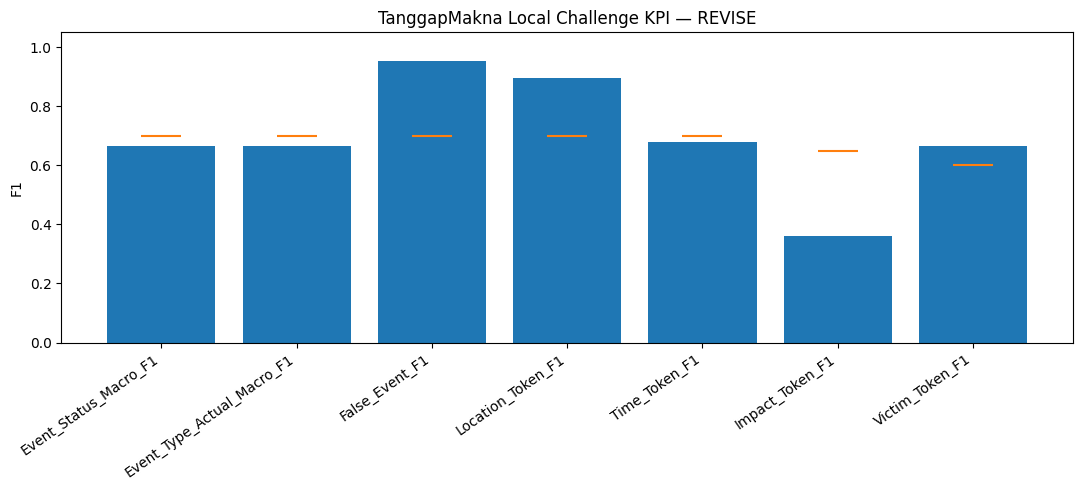

In [ ]:
plot_df = kpi_df.copy()

plt.figure(figsize=(11, 5))

x = np.arange(len(plot_df))

plt.bar(
    x,
    plot_df["Score"],
)

plt.scatter(
    x,
    plot_df["Internal_Target"],
    marker="_",
    s=800,
)

plt.xticks(
    x,
    plot_df["KPI"],
    rotation=35,
    ha="right",
)

plt.ylim(0, 1.05)
plt.ylabel("F1")
plt.title(
    f"TanggapMakna Local Challenge KPI — {FINAL_DECISION}"
)
plt.tight_layout()
plt.show()

## 20. Build report-level comparison and error priority

In [ ]:
def spans_as_string(pred_tokens, role):
    return "; ".join(
        prediction_spans(pred_tokens, role)
    )


report_rows = []

for row in gt.itertuples(index=False):
    rid = row.Report_ID
    pred_tokens = token_predictions[rid]

    pred_event = pred_df[
        pred_df["Report_ID"] == rid
    ].iloc[0]

    result = {
        "Report_ID": rid,
        "Report_Text": row.Report_Text,

        "GT_Event_Status": row.Final_Event_Status,
        "Pred_Event_Status": pred_event["Pred_Event_Status"],

        "GT_Event_Type": row.Final_Event_Type,
        "Pred_Event_Type": pred_event["Pred_Event_Type"],

        "Event_Conflict": pred_event["Event_Conflict"],

        "GT_Place": row.Final_Place,
        "Pred_Place": spans_as_string(
            pred_tokens,
            "PLACE-ARG",
        ),

        "GT_Street": row.Final_Street,
        "Pred_Street": spans_as_string(
            pred_tokens,
            "STREET-ARG",
        ),

        "GT_Time": row.Final_Time,
        "Pred_Time": spans_as_string(
            pred_tokens,
            "TIME-ARG",
        ),

        "GT_Affected": row.Final_Affected_Objects,
        "Pred_Affected": spans_as_string(
            pred_tokens,
            "AFFECTEDOBJECTS-ARG",
        ),

        "GT_Impact": row.Final_Information_Impact,
        "Pred_Impact": spans_as_string(
            pred_tokens,
            "INFORMATION-ARG",
        ),

        "GT_Reason": row.Final_Reason,
        "Pred_Reason": spans_as_string(
            pred_tokens,
            "REASON-ARG",
        ),

        "GT_Officer": row.Final_Officer,
        "Pred_Officer": spans_as_string(
            pred_tokens,
            "OFFICER-ARG",
        ),

        "GT_Death": row.Final_Death_Victim,
        "Pred_Death": spans_as_string(
            pred_tokens,
            "DEATHVICTIM-ARG",
        ),

        "GT_Wound": row.Final_Wound_Victim,
        "Pred_Wound": spans_as_string(
            pred_tokens,
            "WOUNDVICTIM-ARG",
        ),
    }

    priority = "LOW"
    reasons = []

    if result["GT_Event_Status"] != result["Pred_Event_Status"]:
        reasons.append("EVENT_STATUS")
        priority = "CRITICAL"

    if (
        row.Final_Event_Status == "ACTUAL_EVENT"
        and result["GT_Event_Type"] != result["Pred_Event_Type"]
    ):
        reasons.append("EVENT_TYPE")
        priority = "CRITICAL"

    if (
        bool(row.Final_Place or row.Final_Street)
        and not (
            result["Pred_Place"]
            or result["Pred_Street"]
        )
    ):
        reasons.append("LOCATION_MISSED")
        if priority != "CRITICAL":
            priority = "HIGH"

    # Safety-sensitive victim mismatch.
    if result["Pred_Death"] and not row.Final_Death_Victim:
        reasons.append("FALSE_DEATH_VICTIM")
        priority = "CRITICAL"

    if (
        row.Final_Wound_Victim
        and not result["Pred_Wound"]
    ):
        reasons.append("WOUND_VICTIM_MISSED")
        if priority != "CRITICAL":
            priority = "HIGH"

    if not reasons:
        priority = "OK"

    result["Error_Priority"] = priority
    result["Error_Reasons"] = "; ".join(reasons)

    report_rows.append(result)

report_comparison = pd.DataFrame(report_rows)

print("Error priority distribution:")
display(
    report_comparison["Error_Priority"]
    .value_counts()
    .to_frame("count")
)

display(
    report_comparison[
        report_comparison["Error_Priority"]
        .isin(["CRITICAL", "HIGH"])
    ][
        [
            "Report_ID",
            "Report_Text",
            "GT_Event_Status",
            "Pred_Event_Status",
            "GT_Event_Type",
            "Pred_Event_Type",
            "Error_Priority",
            "Error_Reasons",
        ]
    ]
)

Error priority distribution:


,count
Error_Priority,
OK,32
CRITICAL,24
HIGH,4


,Report_ID,Report_Text,GT_Event_Status,Pred_Event_Status,GT_Event_Type,Pred_Event_Type,Error_Priority,Error_Reasons
1,LC002,"Min, air di Gang Melati Rajabasa udah masuk ru...",ACTUAL_EVENT,UNCERTAIN,FLOOD,UNCERTAIN,CRITICAL,EVENT_STATUS; EVENT_TYPE
2,LC003,"Daerah pasar Sukarame udah sepinggang, beberap...",ACTUAL_EVENT,UNCERTAIN,FLOOD,UNCERTAIN,CRITICAL,EVENT_STATUS; EVENT_TYPE
4,LC005,Air naik cepat di sekitar Way Halim sekitar ja...,ACTUAL_EVENT,UNCERTAIN,FLOOD,UNCERTAIN,CRITICAL,EVENT_STATUS; EVENT_TYPE
5,LC006,"Tolong cek wilayah dekat terminal, dari tadi a...",ACTUAL_EVENT,UNCERTAIN,FLOOD,UNCERTAIN,CRITICAL,EVENT_STATUS; EVENT_TYPE
7,LC008,"Di depan sekolah air sudah tinggi, anak-anak s...",ACTUAL_EVENT,UNCERTAIN,FLOOD,UNCERTAIN,CRITICAL,EVENT_STATUS; EVENT_TYPE
9,LC010,"Jalan menuju perumahan di Kemiling tergenang, ...",ACTUAL_EVENT,UNCERTAIN,FLOOD,UNCERTAIN,CRITICAL,EVENT_STATUS; EVENT_TYPE
10,LC011,"Sejak hujan tadi siang selokan meluap, sekaran...",ACTUAL_EVENT,UNCERTAIN,FLOOD,UNCERTAIN,CRITICAL,EVENT_STATUS; EVENT_TYPE
13,LC014,Api terlihat membesar dari salah satu rumah di...,ACTUAL_EVENT,UNCERTAIN,FIRE,UNCERTAIN,CRITICAL,EVENT_STATUS; EVENT_TYPE
16,LC017,Sekitar jam 02.00 terdengar warga berteriak ka...,ACTUAL_EVENT,ACTUAL_EVENT,FIRE,FIRE,HIGH,LOCATION_MISSED
17,LC018,"Tolong cek dekat terminal, ada asap dan bau te...",UNCERTAIN,FALSE_EVENT,FIRE,FIRE,CRITICAL,EVENT_STATUS


## 21. Confusion matrices

In [ ]:
status_cm = confusion_matrix(
    event_eval["Final_Event_Status"],
    event_eval["Pred_Event_Status"],
    labels=STATUS_LABELS,
)

status_cm_df = pd.DataFrame(
    status_cm,
    index=[f"GT_{x}" for x in STATUS_LABELS],
    columns=[f"PRED_{x}" for x in STATUS_LABELS],
)

print("EVENT STATUS CONFUSION MATRIX")
display(status_cm_df)

type_cm = confusion_matrix(
    actual_eval["Final_Event_Type"],
    actual_eval["Pred_Event_Type"],
    labels=ACTUAL_TYPES,
)

type_cm_df = pd.DataFrame(
    type_cm,
    index=[f"GT_{x}" for x in ACTUAL_TYPES],
    columns=[f"PRED_{x}" for x in ACTUAL_TYPES],
)

print("\nACTUAL EVENT TYPE CONFUSION MATRIX")
display(type_cm_df)

EVENT STATUS CONFUSION MATRIX


,PRED_ACTUAL_EVENT,PRED_FALSE_EVENT,PRED_UNCERTAIN
GT_ACTUAL_EVENT,19,0,20
GT_FALSE_EVENT,0,10,0
GT_UNCERTAIN,2,1,8



ACTUAL EVENT TYPE CONFUSION MATRIX


,PRED_FLOOD,PRED_EARTHQUAKE,PRED_FIRE,PRED_ACCIDENT
GT_FLOOD,5,0,0,0
GT_EARTHQUAKE,0,4,0,0
GT_FIRE,0,0,5,0
GT_ACCIDENT,0,0,0,5


## 22. Export Local Evaluation Results

Workbook hasil berisi:
- `Summary`
- `KPI`
- `Role_Metrics`
- `Event_Comparison`
- `Report_Predictions`
- `Critical_High_Errors`
- `Status_Confusion`
- `Type_Confusion`

Ground truth original **tidak diubah**.

In [ ]:
RESULT_XLSX = Path(
    "/content/TanggapMakna_Local_Evaluation_Results.xlsx"
)

summary_df = pd.DataFrame([
    ["Final Decision", FINAL_DECISION],
    ["Reports", len(gt)],
    ["KPI Passed", f"{pass_count}/{len(kpi_df)}"],
    ["Event Status Macro-F1", status_macro_f1],
    ["Actual Event Type Macro-F1", actual_type_macro_f1],
    ["False-event F1", false_f1],
    ["Location Token-F1", product_metrics_dict["Location"]["f1"]],
    ["Time Token-F1", product_metrics_dict["Time"]["f1"]],
    ["Impact Token-F1", product_metrics_dict["Impact"]["f1"]],
    ["Victim Token-F1", product_metrics_dict["Victim"]["f1"]],
], columns=["Metric", "Value"])

with pd.ExcelWriter(
    RESULT_XLSX,
    engine="xlsxwriter",
) as writer:

    summary_df.to_excel(
        writer,
        sheet_name="Summary",
        index=False,
    )

    kpi_df.to_excel(
        writer,
        sheet_name="KPI",
        index=False,
    )

    role_metrics.to_excel(
        writer,
        sheet_name="Role_Metrics",
        index=False,
    )

    event_eval.to_excel(
        writer,
        sheet_name="Event_Comparison",
        index=False,
    )

    report_comparison.to_excel(
        writer,
        sheet_name="Report_Predictions",
        index=False,
    )

    report_comparison[
        report_comparison["Error_Priority"]
        .isin(["CRITICAL", "HIGH"])
    ].to_excel(
        writer,
        sheet_name="Critical_High_Errors",
        index=False,
    )

    status_cm_df.to_excel(
        writer,
        sheet_name="Status_Confusion",
    )

    type_cm_df.to_excel(
        writer,
        sheet_name="Type_Confusion",
    )

    workbook = writer.book

    header_format = workbook.add_format({
        "bold": True,
        "bg_color": "#0F766E",
        "font_color": "#FFFFFF",
        "border": 1,
    })

    wrap_format = workbook.add_format({
        "text_wrap": True,
        "valign": "top",
    })

    for sheet_name, df_export in {
        "Summary": summary_df,
        "KPI": kpi_df,
        "Role_Metrics": role_metrics,
        "Event_Comparison": event_eval,
        "Report_Predictions": report_comparison,
    }.items():

        worksheet = writer.sheets[sheet_name]

        for col_num, value in enumerate(
            df_export.columns.values
        ):
            worksheet.write(
                0,
                col_num,
                value,
                header_format,
            )

        worksheet.freeze_panes(1, 0)
        worksheet.set_column(0, len(df_export.columns)-1, 18)

    writer.sheets["Report_Predictions"].set_column(
        1,
        1,
        70,
        wrap_format,
    )

    if "Critical_High_Errors" in writer.sheets:
        writer.sheets["Critical_High_Errors"].set_column(
            1,
            1,
            70,
            wrap_format,
        )

SUMMARY_JSON = Path(
    "/content/TanggapMakna_Local_Evaluation_Summary.json"
)

SUMMARY_JSON.write_text(
    json.dumps(
        {
            "decision": FINAL_DECISION,
            "reports": len(gt),
            "kpi_passed": pass_count,
            "kpi_total": len(kpi_df),
            "scores": KPI_SCORES,
            "targets": KPI_TARGETS,
        },
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

print("Saved:")
print(" -", RESULT_XLSX)
print(" -", SUMMARY_JSON)
print(" -", RAW_PRED_PATH)

Saved:
 - /content/TanggapMakna_Local_Evaluation_Results.xlsx
 - /content/TanggapMakna_Local_Evaluation_Summary.json
 - /content/TanggapMakna_Local_Raw_Predictions.json


# ⛔ FINAL CHECKPOINT — KIRIM HASIL KE CHATGPT

Kirim **output/screenshot** berikut:

1. Cell 13 — Event Status Macro-F1 + classification report.
2. Cell 14 — Event Type Macro-F1 + classification report.
3. Cell 15 — False-event Precision / Recall / F1.
4. Cell 16 — tabel `role_metrics`.
5. Cell 17 — `product_metrics`.
6. Cell 18 — tabel KPI + `LOCAL EVALUATION DECISION`.
7. Cell 20 — distribusi error priority dan daftar `CRITICAL/HIGH`.
8. Upload `TanggapMakna_Local_Evaluation_Results.xlsx` jika memungkinkan.

## Setelah itu

### Jika FULL GO
**Freeze IndoBERT V2. Stop eksperimen AI. Langsung bangun web.**

### Jika CONDITIONAL GO
Model tetap dipakai sebagai **AI suggestion**, dengan human verification dan rule-based completeness. Kita hanya membatasi klaim/fitur yang lemah.

### Jika REVISE
Jangan tuning dengan 60 test ini. Buat adaptation set terpisah atau revisi product rule, lalu gunakan test baru untuk evaluasi final.

## 23. Optional download results

In [ ]:
from google.colab import files

files.download(
    "/content/TanggapMakna_Local_Evaluation_Results.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>